In [1]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [6]:
df = pd.read_csv('/content/student_scores_linear_regression - student_scores_linear_regression.csv')

In [7]:
print("First five rows of the dataset:")
print(df.head())

First five rows of the dataset:
   study_hours  attendance_percentage  previous_score  final_score
0         1.45                   55.7            35.2        43.47
1         2.00                   57.3            36.8        43.40
2         2.25                   58.9            38.4        47.67
3         2.80                   58.1            40.0        49.03
4         3.35                   59.7            38.1        52.89


In [8]:
print("\nDataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nDescriptive Statistics:")
print(df.describe())

print("\nMissing Values in Each Column:")
print(df.isnull().sum())


Dataset Shape: (80, 4)

Column Names:
Index(['study_hours', 'attendance_percentage', 'previous_score',
       'final_score'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 80 entries, 0 to 79
Data columns (total 4 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   study_hours            80 non-null     float64
 1   attendance_percentage  80 non-null     float64
 2   previous_score         80 non-null     float64
 3   final_score            80 non-null     float64
dtypes: float64(4)
memory usage: 2.6 KB

Descriptive Statistics:
       study_hours  attendance_percentage  previous_score  final_score
count     80.00000              80.000000       80.000000    80.000000
mean       5.27625              74.500000       54.012500    70.857875
std        2.60910              11.700914       12.164062    14.133279
min        0.90000              54.100000       33.600000    43.40

In [9]:
X = df.iloc[:, :-1]
y = df.iloc[:, -1]

print("\nShape of X (Input Feature):", X.shape)
print("Shape of y (Target Variable):", y.shape)


Shape of X (Input Feature): (80, 3)
Shape of y (Target Variable): (80,)


In [10]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("\nTraining Feature Shape:", X_train.shape)
print("Testing Feature Shape:", X_test.shape)
print("Training Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)


Training Feature Shape: (64, 3)
Testing Feature Shape: (16, 3)
Training Target Shape: (64,)
Testing Target Shape: (16,)


In [11]:
model = LinearRegression()
model.fit(X_train, y_train)

print("\nModel training completed successfully.")


Model training completed successfully.


In [12]:
y_pred = model.predict(X_test)

comparison_df = pd.DataFrame({
    'Actual Value': y_test.values,
    'Predicted Value': y_pred
})
print("\nComparison of Actual vs Predicted Values:")
print(comparison_df.head(10))


Comparison of Actual vs Predicted Values:
   Actual Value  Predicted Value
0         82.45        80.629756
1         43.47        41.363159
2         61.67        61.167264
3         81.70        83.403764
4         88.05        88.683760
5         75.82        76.490562
6         69.71        67.724374
7         79.09        77.201479
8         52.89        51.725723
9         73.23        72.685109


In [13]:
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\nModel Evaluation Metrics:")
print("Mean Absolute Error (MAE):", mae)
print("Mean Squared Error (MSE):", mse)
print("Root Mean Squared Error (RMSE):", rmse)
print("R2 Score:", r2)


Model Evaluation Metrics:
Mean Absolute Error (MAE): 1.1640442301884608
Mean Squared Error (MSE): 1.7146556440060317
Root Mean Squared Error (RMSE): 1.309448603041002
R2 Score: 0.9893617988845579


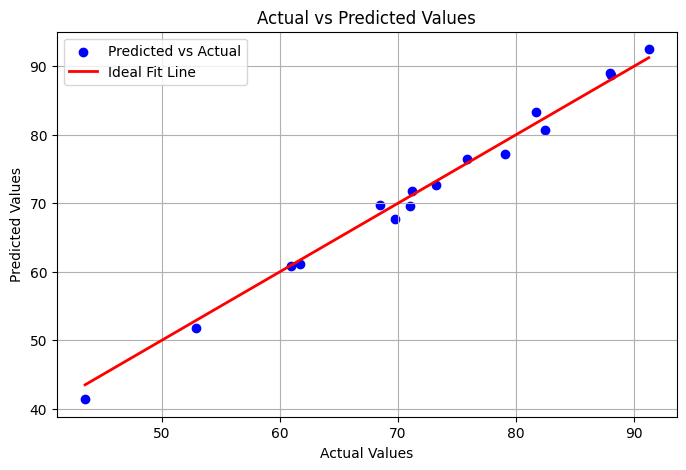

In [14]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, color='blue', label='Predicted vs Actual')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linewidth=2, label='Ideal Fit Line')
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title('Actual vs Predicted Values')
plt.legend()
plt.grid(True)
plt.show()

In [15]:
print("\nCoefficient (Slope):", model.coef_[0])
print("Intercept:", model.intercept_)


Coefficient (Slope): 4.208784445762307
Intercept: 4.532108068185892
